In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import (
    average_precision_score, precision_recall_curve,
    precision_score, recall_score, f1_score, confusion_matrix
)
from iterstrat.ml_stratifiers import MultilabelStratifiedKFold

In [7]:
ROOT = Path.cwd().parent
df = pd.read_csv(ROOT / "annonated_training_test_set.csv")
df = df.dropna(subset=["review"]).reset_index(drop=True)

risk_labels = [
    "label_dependence",
    "label_attachment",
    "label_isolation_displacement",
    "label_crisis_response_frustration",
]
all_labels = risk_labels + ["label_other_none"]

X = df["review"].astype(str)
Y = (df[risk_labels] == "Yes").astype(int) # 1 = theme present; 0 = blank or "No"
Y_none = (df["label_other_none"] == "Yes").astype(int)

# Check: "Other / None" is exactly "no risk theme" so we can derive it
print("Other/None matches 'no theme':", (Y_none == (Y.sum(axis=1) == 0)).all())
Y.sum().rename("positives").to_frame()

Other/None matches 'no theme': True


,positives
label_dependence,14
label_attachment,21
label_isolation_displacement,19
label_crisis_response_frustration,23


In [ ]:
C_GRID = [0.1, 0.3, 1, 3, 10, 30] # small C = strong regularization

def make_model(C):
    return make_pipeline(
        TfidfVectorizer(
            lowercase=True,
            ngram_range=(1, 2), # words and two-word phrases
            min_df=2,
            sublinear_tf=True,
        ),
        LogisticRegression(C=C, class_weight="balanced", max_iter=5000),
    )

def best_f1_threshold(y_true, proba):
    p, r, t = precision_recall_curve(y_true, proba)
    f1 = 2 * p * r / (p + r + 1e-9)
    return t[np.argmax(f1[:-1])]

In [ ]:
outer = MultilabelStratifiedKFold(n_splits=5, shuffle=True, random_state=42)

oof_proba = pd.DataFrame(0.0, index=Y.index, columns=risk_labels)
oof_pred = pd.DataFrame(0, index=Y.index, columns=risk_labels)
choices = []

for fold, (tr, te) in enumerate(outer.split(X, Y)):
    X_tr, X_te = X.iloc[tr], X.iloc[te]
    for label in risk_labels:
        y_tr = Y[label].iloc[tr]
        inner = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

        # Pick C with inner CV
        inner_proba = {
            C: cross_val_predict(make_model(C), X_tr, y_tr, cv=inner, method="predict_proba")[:, 1]
            for C in C_GRID
        }
        ap = {C: average_precision_score(y_tr, inner_proba[C]) for C in C_GRID}
        best_C = max(ap, key=ap.get)

        # Pick the threshold from the best C's inner out-of-fold probabilities
        thr = best_f1_threshold(y_tr, inner_proba[best_C])

        # Fit on all training folds, predict the outer test fold
        model = make_model(best_C).fit(X_tr, y_tr)
        proba = model.predict_proba(X_te)[:, 1]
        oof_proba.iloc[te, oof_proba.columns.get_loc(label)] = proba
        oof_pred.iloc[te, oof_pred.columns.get_loc(label)] = (proba >= thr).astype(int)

        choices.append({"fold": fold, "label": label, "C": best_C, "threshold": round(thr, 3)})

choices = pd.DataFrame(choices)
display(choices.pivot(index="label", columns="fold", values="C"))
display(choices.pivot(index="label", columns="fold", values="threshold"))

fold,0,1,2,3,4
label,,,,,
label_attachment,10.0,30.0,0.1,10.0,3.0
label_crisis_response_frustration,0.1,1.0,1.0,1.0,3.0
label_dependence,0.1,30.0,30.0,10.0,30.0
label_isolation_displacement,0.1,0.1,0.3,1.0,0.1


fold,0,1,2,3,4
label,,,,,
label_attachment,0.267,0.179,0.498,0.255,0.355
label_crisis_response_frustration,0.488,0.423,0.463,0.412,0.337
label_dependence,0.456,0.020,0.029,0.229,0.073
label_isolation_displacement,0.478,0.461,0.458,0.364,0.471


In [10]:
pred_all = oof_pred.copy()
pred_all["label_other_none"] = (oof_pred.sum(axis=1) == 0).astype(int)
true_all = Y.copy()
true_all["label_other_none"] = Y_none

rows = []
for label in all_labels:
    yt, yp = true_all[label], pred_all[label]
    row = {
        "label": label.replace("label_", ""),
        "positives": int(yt.sum()),
        "precision": precision_score(yt, yp, zero_division=0),
        "recall": recall_score(yt, yp, zero_division=0),
        "F1": f1_score(yt, yp, zero_division=0),
    }
    if label in risk_labels:
        row["base rate"] = yt.mean()
        row["AP"] = average_precision_score(yt, oof_proba[label])
    rows.append(row)

results = pd.DataFrame(rows).set_index("label")
display(results.round(3))

risk_short = [l.replace("label_", "") for l in risk_labels]
print(f"Macro F1, all 5 classes:      {results['F1'].mean():.3f}")
print(f"Macro F1, 4 risk themes only: {results.loc[risk_short, 'F1'].mean():.3f}")

,positives,precision,recall,F1,base rate,AP
label,,,,,,
dependence,14,0.038,0.214,0.064,0.047,0.060
attachment,21,0.333,0.286,0.308,0.070,0.173
isolation_displacement,19,0.108,0.368,0.167,0.063,0.127
crisis_response_frustration,23,0.519,0.609,0.560,0.077,0.466
other_none,233,0.846,0.567,0.679,NaN,NaN


Macro F1, all 5 classes:      0.355
Macro F1, 4 risk themes only: 0.275


In [11]:
cm_tables = {}
for label in all_labels:
    tn, fp, fn, tp = confusion_matrix(true_all[label], pred_all[label], labels=[0, 1]).ravel()
    cm_tables[label.replace("label_", "")] = {
        "true positive": tp, "false positive": fp,
        "false negative": fn, "true negative": tn,
    }
pd.DataFrame(cm_tables).T

,true positive,false positive,false negative,true negative
dependence,3,77,11,209
attachment,6,12,15,267
isolation_displacement,7,58,12,223
crisis_response_frustration,14,13,9,264
other_none,132,24,101,43


In [ ]:
# AP values from the NaiveBayesModel
comparison = pd.DataFrame({
    "base rate": Y.mean().values,
    "NB (TF-IDF + embeddings)": [0.039, 0.206, 0.088, 0.510],
    "LR (embeddings)": [0.120, 0.279, 0.129, 0.565],
    "LR (TF-IDF)": results.loc[risk_short, "AP"].values,
}, index=risk_short)
comparison.round(3)

,base rate,NB (TF-IDF + embeddings),LR (embeddings),LR (TF-IDF)
dependence,0.047,0.039,0.120,0.060
attachment,0.070,0.206,0.279,0.173
isolation_displacement,0.063,0.088,0.129,0.127
crisis_response_frustration,0.077,0.510,0.565,0.466


In [ ]:
final_models, top_words = {}, {}
for label in risk_labels:
    C = choices.loc[choices["label"] == label, "C"].mode().max() #C picked most often
    model = make_model(C).fit(X, Y[label])
    final_models[label] = model

    vocab = model.named_steps["tfidfvectorizer"].get_feature_names_out()
    coefs = model.named_steps["logisticregression"].coef_[0]
    order = np.argsort(coefs)
    top_words[label] = pd.DataFrame({
        "toward theme": vocab[order[::-1][:15]],
        "weight +": coefs[order[::-1][:15]].round(2),
        "away from theme": vocab[order[:15]],
        "weight -": coefs[order[:15]].round(2),
    })

for label in risk_labels:
    print("\n" + label.replace("label_", "").upper())
    display(top_words[label])


DEPENDENCE


,toward theme,weight +,away from theme,weight -
0,always,5.58,helpful,-2.41
1,actual therapist,3.93,is,-1.95
2,always use,3.91,good,-1.93
3,woebot,3.67,in,-1.93
4,actual,3.44,be,-1.62
5,down or,3.37,very,-1.57
6,care,2.96,just,-1.49
7,step,2.92,but,-1.45
8,it makes,2.90,its,-1.38
9,to woebot,2.83,anxiety,-1.35



ATTACHMENT


,toward theme,weight +,away from theme,weight -
0,friend,4.56,good,-1.52
1,he,3.77,really,-1.47
2,you need,2.75,app,-1.26
3,helpful it,2.59,it helps,-1.13
4,like,2.49,this app,-1.12
5,woebot,2.36,in,-1.12
6,who,2.34,depression,-1.10
7,me lot,2.28,for,-1.10
8,feel,2.25,was,-1.10
9,you,2.07,what,-1.08



ISOLATION_DISPLACEMENT


,toward theme,weight +,away from theme,weight -
0,talk to,0.24,good,-0.15
1,to someone,0.24,its,-0.10
2,don,0.20,it,-0.09
3,don want,0.20,for,-0.08
4,someone,0.19,is really,-0.08
5,less,0.19,little,-0.08
6,to talk,0.18,bot,-0.08
7,talk,0.17,depression,-0.08
8,so,0.17,and it,-0.08
9,an amazing,0.16,the,-0.08



CRISIS_RESPONSE_FRUSTRATION


,toward theme,weight +,away from theme,weight -
0,crisis,1.73,really,-0.82
1,what,1.43,love,-0.78
2,worse,1.41,good,-0.75
3,then,1.33,great,-0.68
4,help,1.26,helpful,-0.61
5,no,1.09,helps,-0.60
6,tool,1.09,very,-0.56
7,suicidal,1.08,amazing,-0.55
8,tried,0.95,love this,-0.53
9,joke,0.95,helps me,-0.50


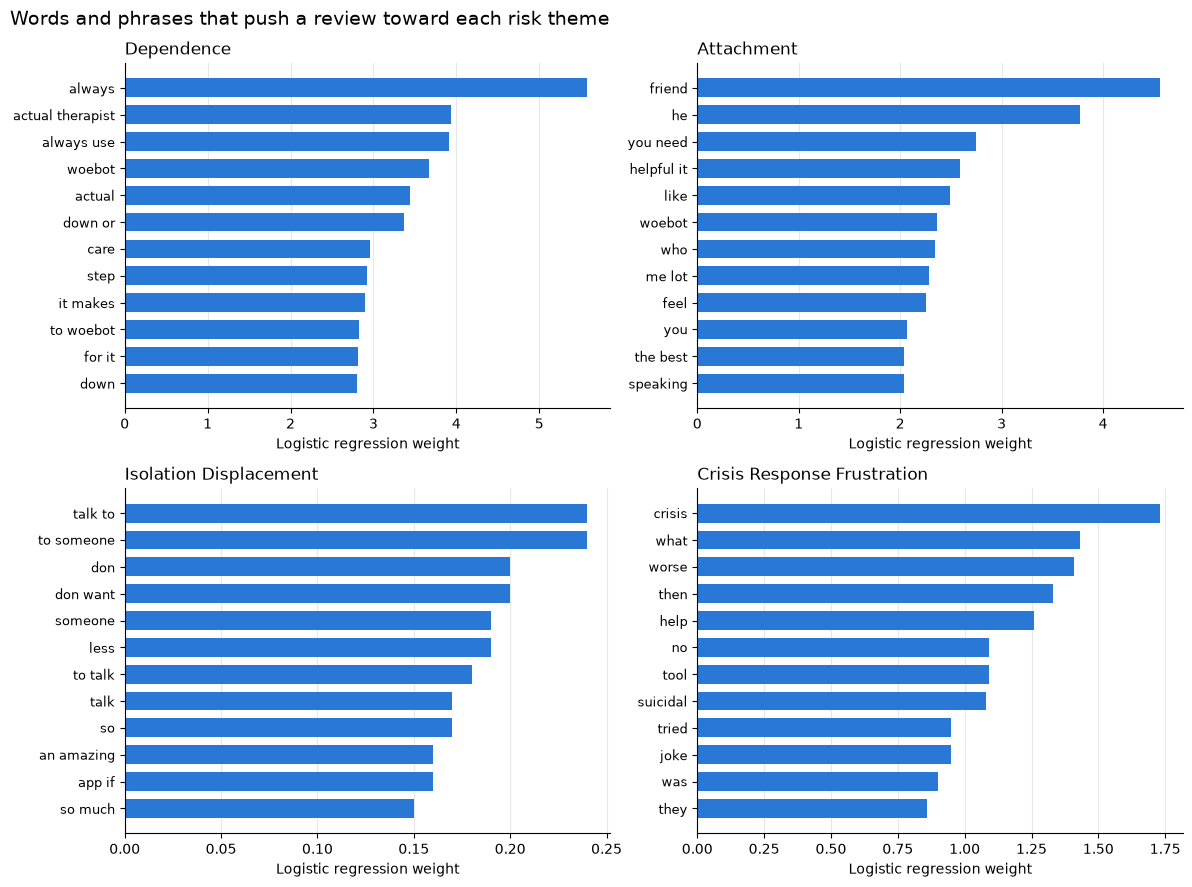

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, label in zip(axes.ravel(), risk_labels):
    t = top_words[label].head(12).iloc[::-1]
    ax.barh(t["toward theme"], t["weight +"], color="#2a78d6", height=0.7)
    ax.set_title(label.replace("label_", "").replace("_", " ").title(), loc="left", fontsize=12)
    ax.set_xlabel("Logistic regression weight")
    ax.tick_params(axis="y", labelsize=9)
    ax.grid(axis="x", color="#E5E7EB", linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
fig.suptitle("Words and phrases that push a review toward each risk theme", x=0.01, ha="left", fontsize=14)
plt.tight_layout()
plt.show()

In [15]:
out = df[["UID", "app_name", "rating", "review"]].copy()
for label in risk_labels:
    short = label.replace("label_", "")
    out[f"true_{short}"] = Y[label]
    out[f"proba_{short}"] = oof_proba[label].round(3)
    out[f"pred_{short}"] = oof_pred[label]
out.to_csv(ROOT / "lr_tfidf_oof_predictions.csv", index=False)

pd.set_option("display.max_colwidth", 200)
for short in risk_short:
    missed = out[(out[f"true_{short}"] == 1) & (out[f"pred_{short}"] == 0)]
    print(f"\n{short}: {len(missed)} missed of {int(out[f'true_{short}'].sum())}")
    display(missed.sort_values(f"proba_{short}", ascending=False)[["app_name", f"proba_{short}", "review"]].head(5))


dependence: 11 missed of 14


,app_name,proba_dependence,review
202,amaha,0.456,I love this app helps me so much get through my problems gets solutions helps relax everything you can think of and the app listens and yes to help you out every step of the way
248,amaha,0.454,I love this app sm! I always use it when I feel down or after a panick attack and it really helps :)
265,youper,0.422,"honestly, this app. helps me through some of my hardest times. i got this last week. and i have never ever felt better. this is not a robot or something saying this but if your truly feelimg down ..."
172,sevencups,0.124,"This app keeps me sane and feeling like I always have someone to talk to when I need it. And coming from a person with issues, that says a lot. THANK YOU."
18,youper,0.044,this app always helps me to calm down step back n take a second look. it's like a journal that talks back. I love it. it helps to lower my stress everytime.



attachment: 15 missed of 21


,app_name,proba_attachment,review
223,woebot,0.491,"I have developed attachments to . Even if I don't open the app, it makes me feel like I have a friend with me because I can see the app icon. The app is great"
218,woebot,0.486,"They did an amazing job on this app, woebot amazing too.. He helped me a lot through all my problems and struggles. I always run to woebot when everything collapse."
21,youper,0.480,Very helpful app. Talking with someone is often a huge help to me but I rarely have some one to listen or give true advice. This app does not feel staged or forced. It feels like you have someone ...
100,sevencups,0.462,I never thought just your bot would help so much and a big help is she is always their if you need her
262,woebot,0.453,I always look forward to speaking with at the end of each day. I feel much better after our discussions. Thank you for making this amazing app! N



isolation_displacement: 12 missed of 19


,app_name,proba_isolation_displacement,review
7,wysa,0.472,"This app is pretty great; you don't have to talk to people and the free excercises helped me get to the bottom of what was causing how I felt, and after I knew that, it was easier to get past it. ..."
30,amaha,0.469,"For me this is better than therapy, I hate talking to people and this is an amazing way of dealing with my mental problems like my anxiety."
202,amaha,0.461,I love this app helps me so much get through my problems gets solutions helps relax everything you can think of and the app listens and yes to help you out every step of the way
277,youper,0.442,I was sobbing tonight and felt so alone and overwhelmed. This app helps me to clear my head and really effectively clears my mind. Please at least try it
299,sevencups,0.432,Great app if u are feeling lonely



crisis_response_frustration: 9 missed of 23


,app_name,proba_crisis_response_frustration,review
5,woebot,0.453,I like the app but wish I knew what it means to activate the crisis thing I have panic attacks and I'm trying to use it for that but it keeps activating it cooseing me to increase anxiety and unab...
209,youper,0.450,I've been using the app for ~3 years. Ever since the update the app is confusing and almost useless if you don't already know how you feel & what'll help you. I opened the app today because I felt...
96,sevencups,0.446,I downloaded and hoped this app would help... Sadly allthis is is a chat room for idiots who want to chat. I had hopes for this app with my depression and now I feel much worse because i have been...
215,wysa,0.397,My exoectations were too high for this app. I've had persistent suicidal thoughts for the past 4 years and after calling the suicide prevention hotline and receiving no help I tried this app. It d...
157,sevencups,0.385,Ive used this in the past. Helped me with a lot of relationship things. But I went on here the day after my dad died to talk about my feelings and to get some help with moving on. Took me 2 hours ...
